Johannes Standhal og Rozalia Ciupka

# CA5

### Imports

In [261]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Pipelines and dimension reduction
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Models
from sklearn.linear_model import LinearRegression

# Model selection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score

# Evaluation
from sklearn.metrics import mean_squared_error

### Reading data

In [262]:
df_train = pd.read_csv("train.csv")
df_submission = pd.read_csv("test.csv")

### Data exploration and visualisation

In [263]:
df_train.info()

categorical = ['smoking_status']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367500 entries, 0 to 367499
Data columns (total 17 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            367500 non-null  int64  
 1   age                           345653 non-null  float64
 2   sleep_duration_hrs            340323 non-null  float64
 3   sleep_quality_score           357702 non-null  float64
 4   cardio_mins_wk                355386 non-null  float64
 5   water_intake_liters           358969 non-null  float64
 6   screen_time_recreational_hrs  338865 non-null  float64
 7   social_media_hrs              362207 non-null  float64
 8   blood_pressure_sys            357789 non-null  float64
 9   diet_ultra_processed_pct      354171 non-null  float64
 10  diet_omega3_freq              344987 non-null  float64
 11  smoking_status                342146 non-null  object 
 12  alcohol_drinks_wk             346938 non-nul

In [264]:
# Check for missing values, we have none
print(f"missing values in training data: {df_train.isna().sum()}")

missing values in training data: id                                  0
age                             21847
sleep_duration_hrs              27177
sleep_quality_score              9798
cardio_mins_wk                  12114
water_intake_liters              8531
screen_time_recreational_hrs    28635
social_media_hrs                 5293
blood_pressure_sys               9711
diet_ultra_processed_pct        13329
diet_omega3_freq                22513
smoking_status                  25354
alcohol_drinks_wk               20562
novel_learning_hrs_wk           26727
social_connection_score         24873
chronic_stress_score            17929
target                              0
dtype: int64


In [265]:
# Check for duplicate rows, we have none
print("Duplicate rows:", df_train.duplicated().sum())

Duplicate rows: 0


In [266]:
# Class distribution in the training data
print(df_train["target"].value_counts(normalize=True))

df_train = df_train.drop(['id', 'target'], axis=1)

target
30    0.229078
28    0.199118
27    0.177810
29    0.167312
26    0.120332
25    0.062846
24    0.026590
23    0.010397
22    0.004101
21    0.001480
20    0.000661
19    0.000196
18    0.000073
17    0.000005
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Correlation map from training data')

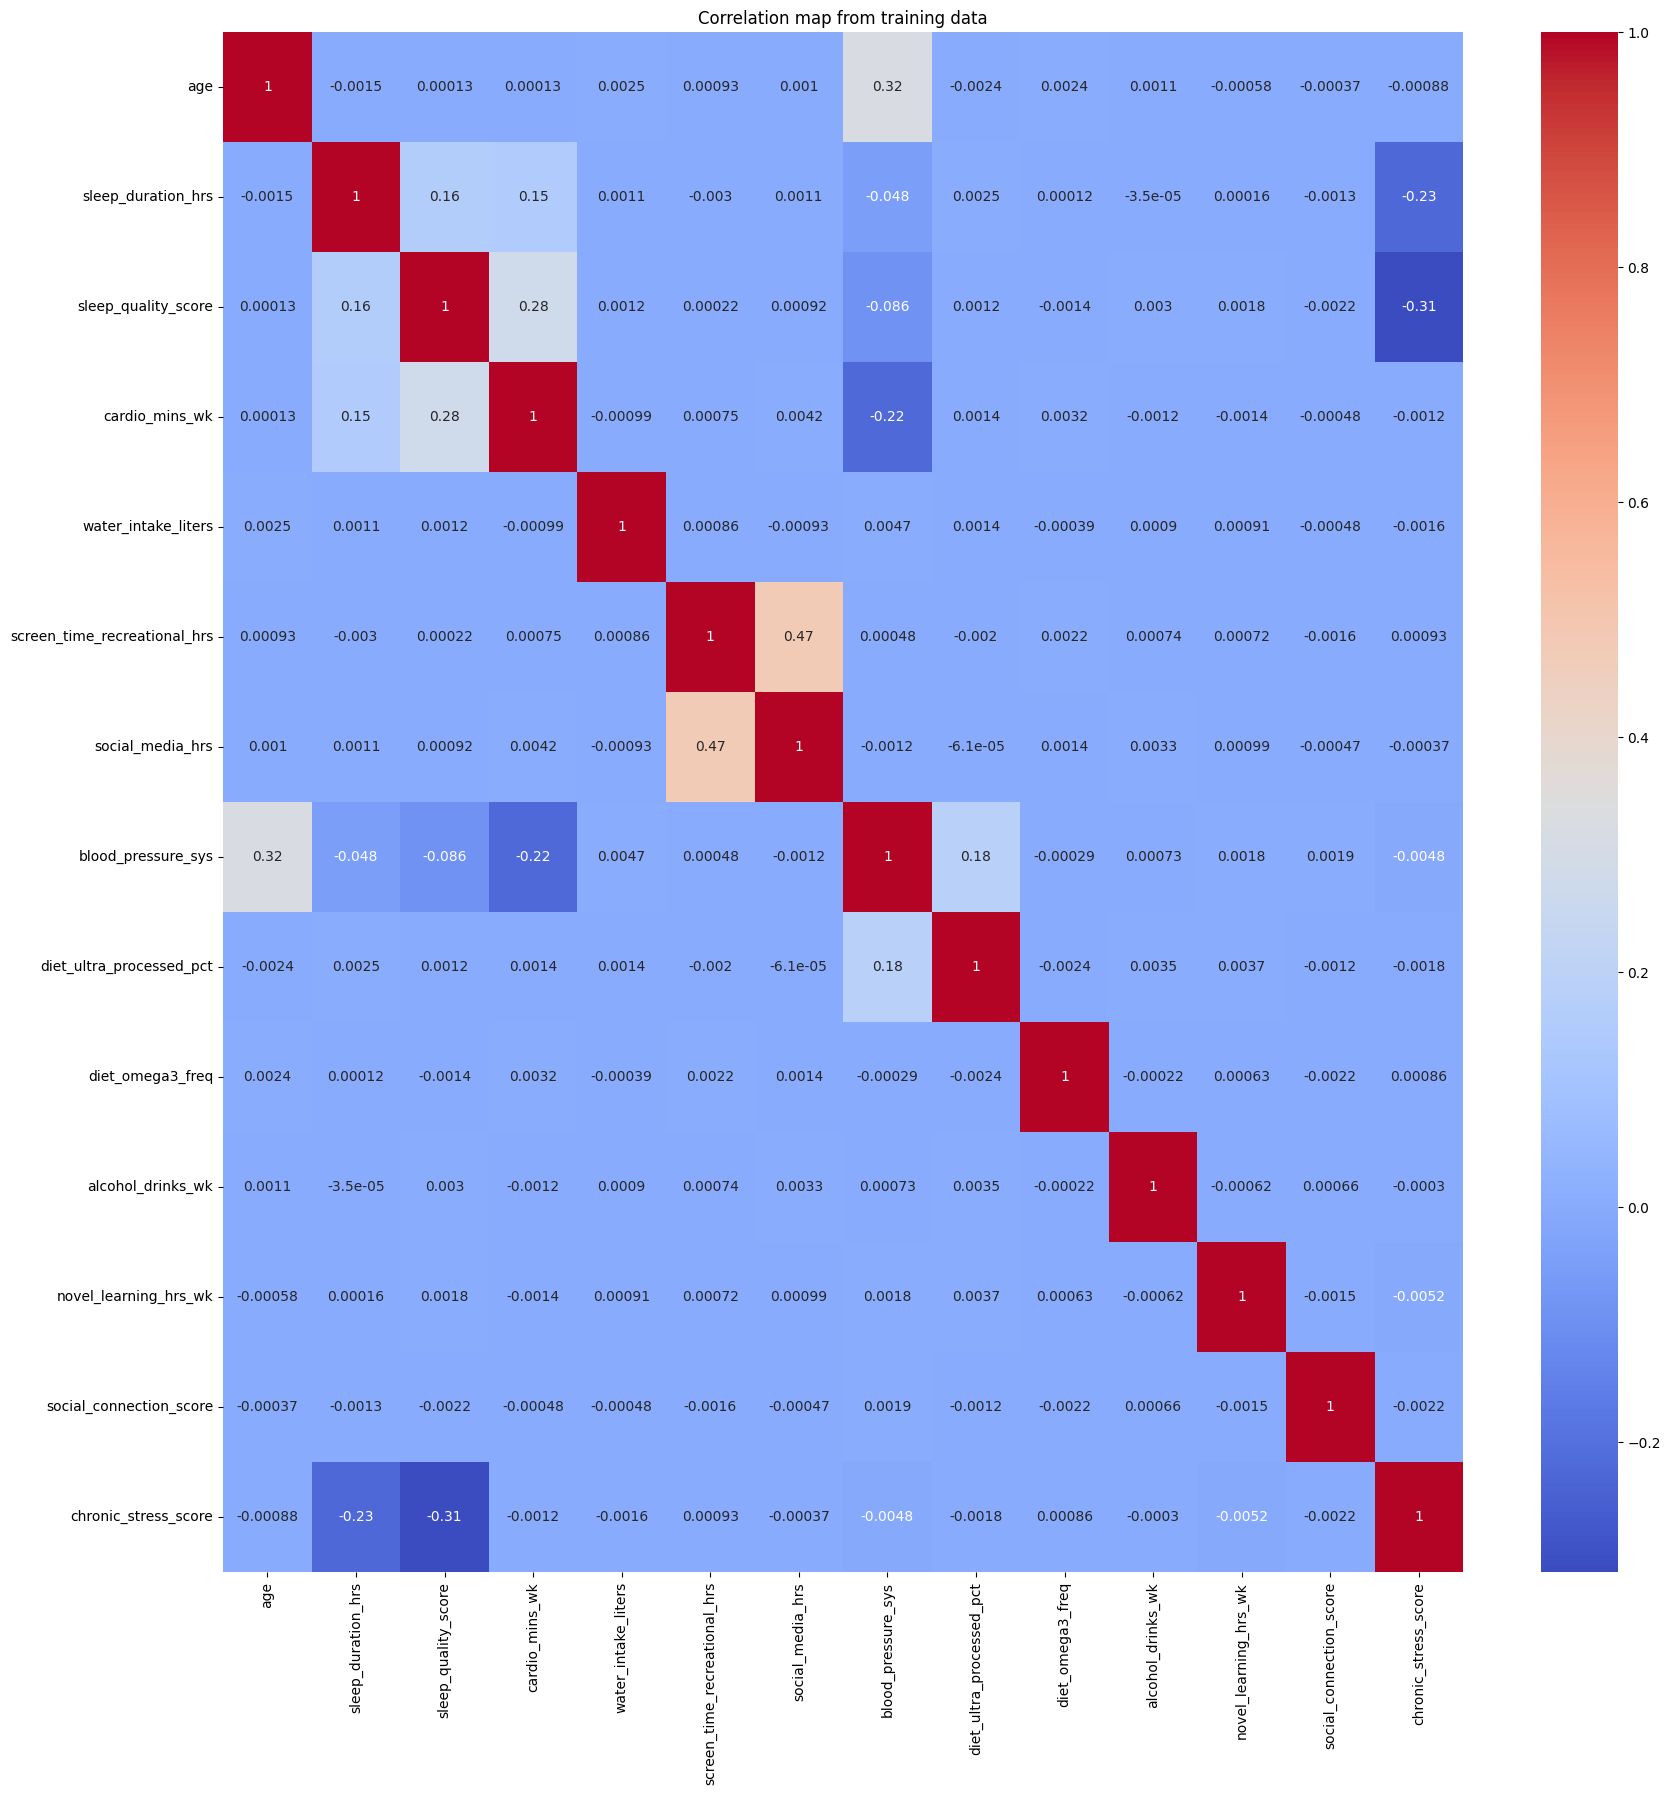

In [267]:
# creating a new dataframe with only numerical features for correlation map and whisker plots
df_numeric = df_train.drop(columns=categorical)

# correlation map from numerical features, modified code from lecture 12
plt.figure(figsize=(20,20))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation map from training data")

In [268]:
df_numeric = df_numeric.dropna(axis=0)

We drop the missing values here to make the boxplot. In data cleaning, we will handle those values in another way.

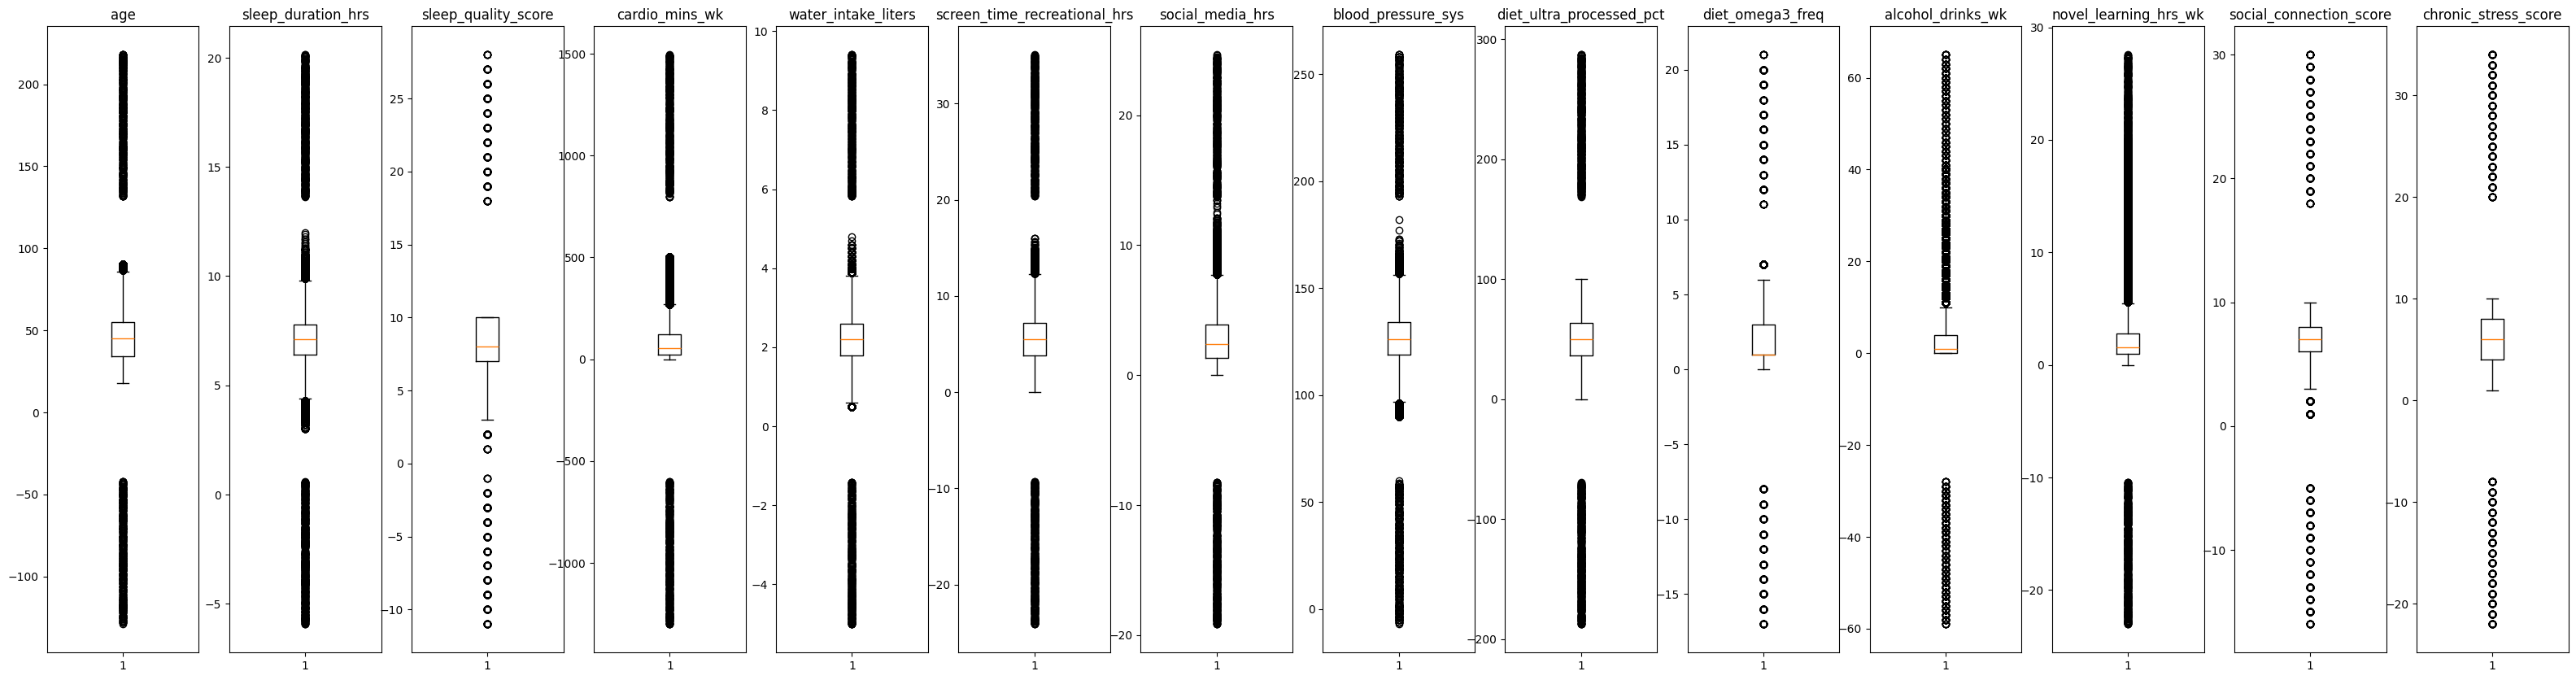

In [269]:
# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_numeric.columns), figsize=(40,10))

for i, column in enumerate(df_numeric.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_numeric[column])

In [270]:
# Checking for negative values
for columns in df_numeric.columns:
    invalid = df_numeric[(df_numeric[columns] < 0)]
    print(len(invalid))
    

433
420
477
413
437
456
452
47
459
455
520
485
464
450


### Data cleaning

First we test the cleaning on the dataframe from data exploration. Thereafter we do the same cleaning on a fresh train dataset.

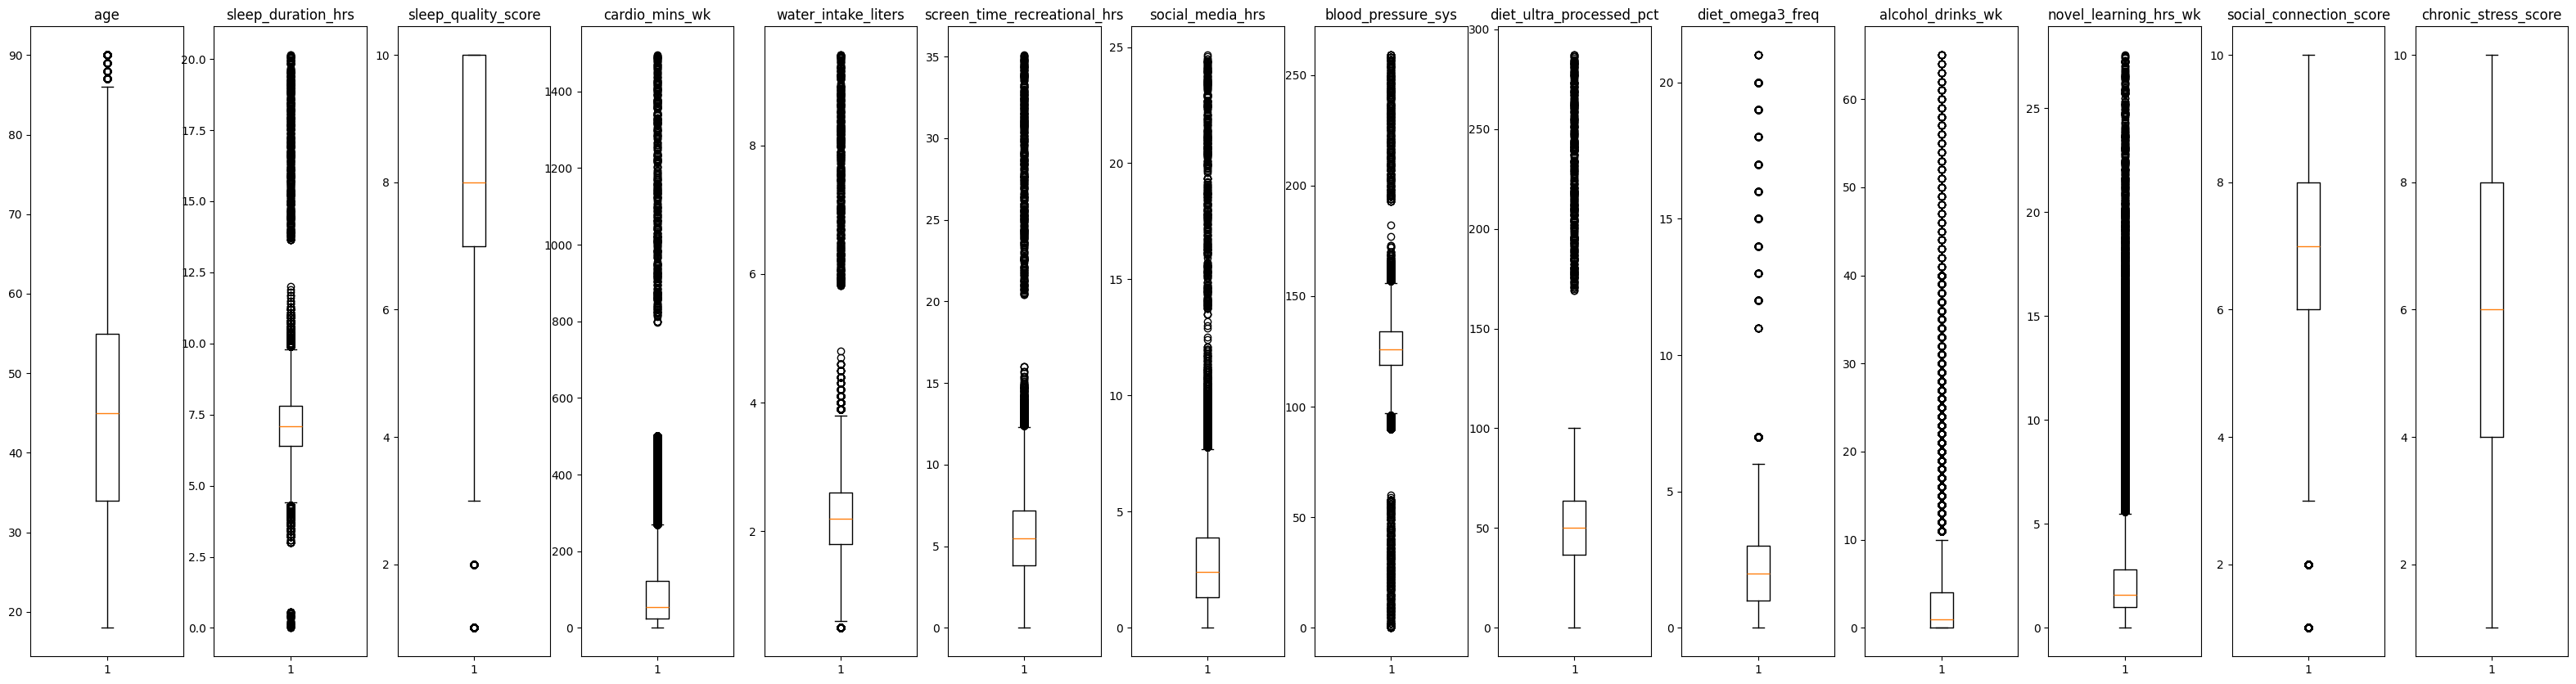

In [271]:
# Dropping negative values
for column in df_numeric.columns:
    if column == 'sleep_quality_score' or column == 'social_connection_score' or column == 'chronic_stress_score':
        df_numeric[column] = df_numeric[column].clip(lower=1, upper=10)
    elif column == 'age':
        df_numeric = df_numeric[df_numeric[column] >= 18] 
        df_numeric = df_numeric[df_numeric[column] <= 90]
    else:
        df_numeric = df_numeric[df_numeric[column] >= 0]

# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_numeric.columns), figsize=(40,10))

for i, column in enumerate(df_numeric.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_numeric[column])


In [272]:
df_train = pd.read_csv('train.csv')

df_train.columns 

Index(['id', 'age', 'sleep_duration_hrs', 'sleep_quality_score',
       'cardio_mins_wk', 'water_intake_liters', 'screen_time_recreational_hrs',
       'social_media_hrs', 'blood_pressure_sys', 'diet_ultra_processed_pct',
       'diet_omega3_freq', 'smoking_status', 'alcohol_drinks_wk',
       'novel_learning_hrs_wk', 'social_connection_score',
       'chronic_stress_score', 'target'],
      dtype='object')

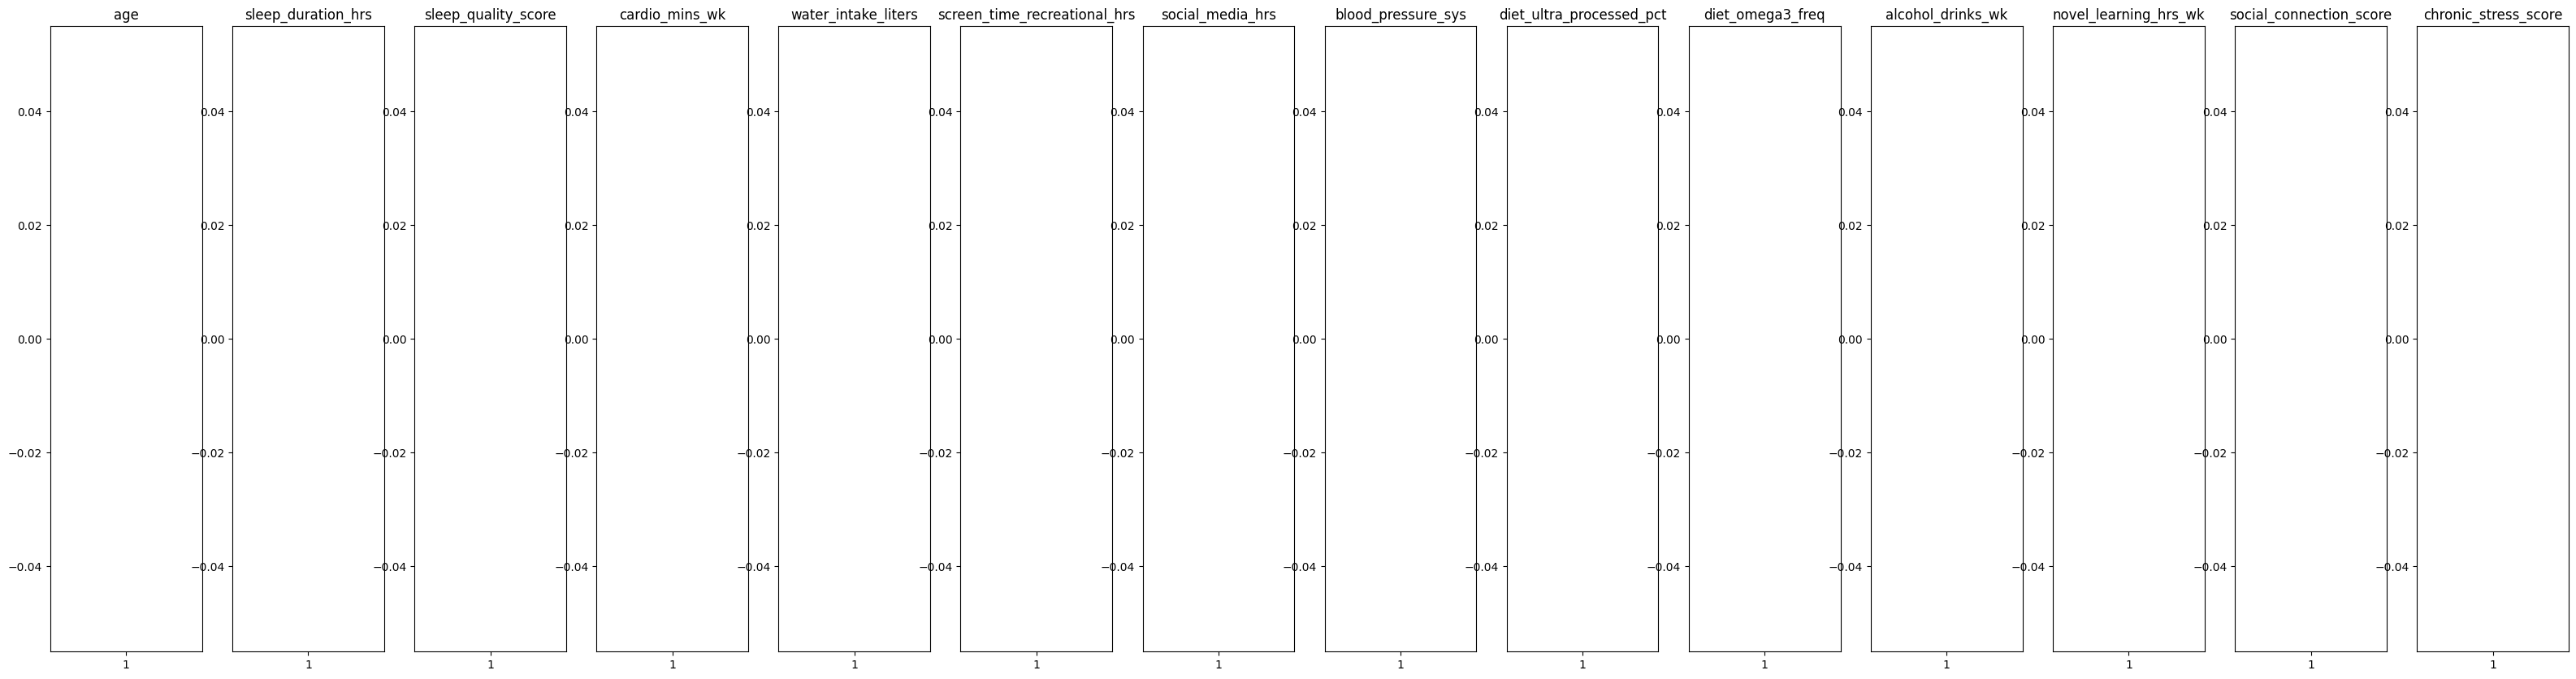

In [273]:
def cleaning(df):
    skip_cols = ['id', 'smoking_status', 'target']
    special = ['diet_ultra_processed_pct', 'sleep_quality_score', 'social_connection_score', 'chronic_stress_score']

    lower_limits = [None, 18, 0, 1, 0, 0, 0, 0, 60, 1, 0, None, 0, 0, 1, 1, None]
    upper_limits = [None, 90, 14, 10, 1000, 6, 20, 20, 180, 100, 7, None, 100, 140, 10, 10, None]

    for i, col in enumerate(df.columns):
        if lower_limits[i] is None:
            continue

        elif col in special:
            continue

        df = df[df[col] >= lower_limits[i]]
        df = df[df[col] <= upper_limits[i]]
        

    # df = df[df['age'] >= 18]
    # df = df[df['age'] <= 90]

    # df = df[df['sleep_duration_hrs'] <= 14]
    # df = df[df['cardio_mins_wk'] <= 1000]
    # df = df[df['water_intake_liters'] <= 6]
    # df = df[df['screen_time_recreational_hrs'] <= 20]
    # df = df[df['social_media_hrs'] <= 20]
    # df = df[df['blood_pressure_sys'] <= 180]
    # df = df[df['diet_omega3_freq'] <= 7]
    # df = df[df['novel_learning_hrs_wk'] <= 24]

    # df['diet_ultra_processed_pct'] = df['diet_ultra_processed_pct'].clip(lower=0, upper=100)

    # df['sleep_quality_score'] = df['sleep_quality_score'].clip(lower=1, upper=10)
    # df['social_connection_score'] = df['social_connection_score'].clip(lower=1, upper=10)
    # df['chronic_stress_score'] = df['chronic_stress_score'].clip(lower=1, upper=10)

    return df

df_train = df_train.drop(['id', 'smoking_status', 'target'], axis=1)
df_train = cleaning(df_train)

# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_train.columns), figsize=(40,10))

for i, column in enumerate(df_train.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_train[column])

### Data preprocessing and visualisation

In [274]:
x_train = df_train.drop(columns=["target", "id"])
y_train = df_train["target"]

X_train, X_test, Y_train, Y_test = train_test_split(x_train, y_train, test_size=0.4, random_state=42, stratify=y_train) 

KeyError: "['target', 'id'] not found in axis"

In [ ]:
# Naming the columns with categorical data for preprocessing 
# (redoing this as we dropped some features)
categorical_features = [
    "smoking_status"
]

# Getting the columns with numerical data for preprocessing
numerical_features = []
for col in X_train.columns:
    if col not in categorical_features:
        numerical_features.append(col)


# Numerical preprocessing
numerical_pipeline = Pipeline([
    # We dont have any missing data, but adding imputer for robustness as mentioned in the lecture
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing with no scaling
numerical_pipeline_no_scaling = Pipeline([
    # Some models dont require scaling
    ('imputer', SimpleImputer(strategy='median')),
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    # One hot encoding because we have no ordinal features
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

In [ ]:
# Preproccesor
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Preproccesor without scaling
preprocessor_no_scaling = ColumnTransformer([
    ('numerical', numerical_pipeline_no_scaling, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

### Modelling

In [ ]:
# PCR
cv = KFold(n_splits=10, shuffle=True, random_state=42)

PCR_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearRegression())
])

# Apply pipeline to grid search with cross-validation
PCR_scores = cross_val_score(
    PCR_pipeline,
    X_train,
    Y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

PCR_score_train = np.mean(PCR_scores)

print(PCR_score_train*(-1))

### Final evaluation

### Kaggle submission